In [1]:
import sys
print(sys.executable)

/Users/xiyuanzhu/anaconda3/envs/qmim_project/bin/python


In [5]:

import pandas as pd
import numpy as np

# 1. Load 2018 CRSP data
df = pd.read_csv(
    "crsp_2018.csv",
    low_memory=False
)

df.columns = df.columns.str.lower().str.strip()
df["dlycaldt"] = pd.to_datetime(df["dlycaldt"])

for col in ["dlycap", "dlyprcvol", "dlyret"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Confirm this is the 2018 dataset
print("Data range:",
      df["dlycaldt"].min(),
      df["dlycaldt"].max())

assert df["dlycaldt"].dt.year.eq(2018).all(), \
    "The file contains dates outside 2018."

# 2. Calculate 60-day average trading value
# Use each stock's preceding observations, including year-end
df = df.sort_values(["permno", "dlycaldt"])

df["adv60"] = (
    df.groupby("permno")["dlyprcvol"]
    .transform(
        lambda s: s.where(s >= 0)
        .rolling(60, min_periods=60).mean()
    )
)

# 3. Find final trading day of 2018
selection_date = df["dlycaldt"].max()

snapshot = df.loc[
    df["dlycaldt"] == selection_date
].copy()

print("Selection date:", selection_date)
print("Stocks on date:", snapshot["permno"].nunique())

# 4. Apply historical security eligibility
eligible = snapshot.loc[
    (snapshot["securitytype"] == "EQTY") &
    (snapshot["securitysubtype"] == "COM") &
    (snapshot["sharetype"] == "NS") &
    (snapshot["usincflg"] == "Y") &
    (snapshot["issuertype"].isin(["ACOR", "CORP"])) &
    (snapshot["primaryexch"].isin(["N", "A", "Q"]))
].copy()

print("Eligible common equities:", len(eligible))

# 5. Apply the proposed liquidity requirement
MIN_ADV = 10_000_000

eligible = eligible.loc[
    (eligible["adv60"] >= MIN_ADV) &
    (eligible["dlycap"] > 0)
].copy()

print("After liquidity screening:", len(eligible))

# 6. Choose the largest security per company
# to avoid selecting two share classes of one company
eligible = eligible.sort_values(
    ["dlycap", "permno"],
    ascending=[False, True]
)

eligible = eligible.drop_duplicates(
    subset="permco",
    keep="first"
)

# 7. Select top 100 by historical market cap
top100_2019 = eligible.head(100).copy()

top100_2019["investment_year"] = 2019
top100_2019["selection_date"] = selection_date

print("\nSelected stocks:", len(top100_2019))

assert len(top100_2019) == 100, \
    "Fewer than 100 eligible companies."

display(
    top100_2019[
        ["permno", "ticker", "dlycap",
         "adv60", "selection_date"]
    ].head(10)
)


Data range: 2018-01-02 00:00:00 2018-12-31 00:00:00
Selection date: 2018-12-31 00:00:00
Stocks on date: 7545
Eligible common equities: 3600
After liquidity screening: 1498

Selected stocks: 100


,permno,ticker,dlycap,adv60,selection_date
1863291,10107,MSFT,7.803623e+08,4.479642e+09,2018-12-31
1864564,14593,AAPL,7.460791e+08,8.125744e+09,2018-12-31
1868588,84788,AMZN,7.344168e+08,1.263144e+10,2018-12-31
1864535,14542,GOOG,3.621300e+08,2.147617e+09,2018-12-31
1867021,22111,JNJ,3.461093e+08,1.359303e+09,2018-12-31
1867300,47896,JPM,3.246266e+08,1.929648e+09,2018-12-31
1863940,13407,FB,3.149393e+08,3.817651e+09,2018-12-31
1863421,11850,XOM,2.887033e+08,1.216888e+09,2018-12-31
1868449,83443,BRK,2.782551e+08,1.098742e+09,2018-12-31
1867389,55976,WMT,2.706250e+08,9.221766e+08,2018-12-31


In [9]:


top100_2019.to_csv(
    "universe_2019.csv",
    index=False
)



In [11]:


import pandas as pd

returns = pd.read_csv("selected2018.csv")

returns["dlycaldt"] = pd.to_datetime(returns["dlycaldt"])
returns["dlyret"] = pd.to_numeric(
    returns["dlyret"], errors="coerce"
)

# Dates × stocks
R = returns.pivot(
    index="dlycaldt",
    columns="permno",
    values="dlyret"
)

print("Matrix shape:", R.shape)
print("Stocks:", R.shape[1])
print("Missing values:", R.isna().sum().sum())

display(R.head())


/var/folders/1t/mtsckvf93mg3rddkkbxt1tvr0000gn/T/ipykernel_90928/2773152583.py:3: DtypeWarning: Columns (28: dlyretmissflg) have mixed types. Specify dtype option on import or set low_memory=False.
  returns = pd.read_csv("selected2018.csv")


Matrix shape: (754, 100)
Stocks: 100
Missing values: 421


permno,10104,10107,10145,11308,11850,12060,12308,12369,12490,13407,...,89626,90215,90441,91233,91937,92602,92611,92655,93002,93436
dlycaldt,,,,,,,,,,,,,,,,,,,,,
2016-01-04,-0.017246,-0.012257,-0.009655,-0.013035,-0.006286,-0.014125,-0.030421,-0.020582,-0.012135,-0.023314,...,-0.021302,-0.021556,-0.020987,-0.026192,-0.004346,-0.010352,-0.023856,-0.010031,-0.019773,-0.069164
2016-01-05,-0.003077,0.004562,0.008190,0.003538,0.008521,0.000977,-0.013294,-0.026419,-0.000736,0.004989,...,0.007894,0.004432,0.000000,0.001899,0.032606,0.010000,0.007530,0.001889,-0.033455,0.000090
2016-01-06,0.005051,-0.018165,-0.011314,-0.005405,-0.008321,-0.015940,-0.004910,-0.035769,-0.005006,0.002336,...,-0.004923,-0.009864,0.004889,-0.015265,-0.004227,-0.000228,-0.013111,-0.010199,-0.030759,-0.019648
2016-01-07,-0.021776,-0.034783,-0.029441,-0.016541,-0.016006,-0.042314,-0.003901,-0.040934,-0.017090,-0.049043,...,-0.015743,-0.026085,-0.031063,-0.018318,0.011486,-0.006830,-0.019663,-0.029440,-0.031810,-0.015477
2016-01-08,-0.011130,0.003067,-0.008062,-0.002643,-0.020202,-0.017950,0.007257,-0.015338,-0.009258,-0.006025,...,-0.014852,-0.014401,0.000000,-0.019097,-0.015552,-0.006189,-0.012332,-0.017218,-0.006587,-0.021563


In [13]:

# Missing returns by stock
missing_by_stock = R.isna().sum().sort_values(ascending=False)

print("Top 10 stocks with missing returns:")
print(missing_by_stock.head(10))

print("\nStocks with no missing returns:")
print((missing_by_stock == 0).sum())

print("\nStocks with more than 10 missing returns:")
print((missing_by_stock > 10).sum())

# Check complete trading days
print("\nTotal trading days:", len(R))
print("Days with all 100 returns:", R.dropna().shape[0])


Top 10 stocks with missing returns:
permno
16851    421
10104      0
69032      0
77274      0
77178      0
76841      0
76076      0
75825      0
75510      0
75186      0
dtype: int64

Stocks with no missing returns:
99

Stocks with more than 10 missing returns:
1

Total trading days: 754
Days with all 100 returns: 333


In [15]:

# Use the previously screened eligible stocks
# already sorted by market capitalisation

ranked = eligible.sort_values(
    ["dlycap", "permno"],
    ascending=[False, True]
)

# Rank 101 = first replacement candidate
candidate = ranked.iloc[100]

print("Replacement candidate:")
print(candidate[[
    "permno", "ticker", "dlycap", "adv60"
]])


Replacement candidate:
permno               12052
ticker                  GD
dlycap          46557741.5
adv60     323999048.093333
Name: 1863441, dtype: object


In [17]:

# Read GD historical returns
gd = pd.read_csv("GDreplacement.csv")

gd["dlycaldt"] = pd.to_datetime(gd["dlycaldt"])
gd["dlyret"] = pd.to_numeric(gd["dlyret"], errors="coerce")

# Convert to daily return series
gd_returns = (
    gd[gd["permno"] == 12052]
    .set_index("dlycaldt")["dlyret"]
    .reindex(R.index)
)

print("GD valid returns:", gd_returns.count())
print("GD missing returns:", gd_returns.isna().sum())


GD valid returns: 754
GD missing returns: 0


In [19]:

# Replace incomplete stock with GD
R_clean = R.drop(columns=[16851]).copy()
R_clean[12052] = gd_returns

print("Final matrix shape:", R_clean.shape)
print("Remaining missing values:", R_clean.isna().sum().sum())


Final matrix shape: (754, 100)
Remaining missing values: 0


In [21]:

from sklearn.covariance import LedoitWolf
import numpy as np

# Estimate covariance from 2016–2018 daily returns
lw = LedoitWolf().fit(R_clean.values)

cov_daily = lw.covariance_

print("Covariance shape:", cov_daily.shape)
print("Shrinkage:", round(lw.shrinkage_, 4))
print("Estimated observations:", len(R_clean))


Covariance shape: (100, 100)
Shrinkage: 0.0235
Estimated observations: 754


In [23]:

%pip -q install cvxpy

import cvxpy as cp
import numpy as np

def optimise_portfolio(cov, cap=None):
    n = cov.shape[0]
    w = cp.Variable(n)

    # Long-only, fully invested
    constraints = [
        cp.sum(w) == 1,
        w >= 0
    ]

    # Individual position limit
    if cap is not None:
        constraints.append(w <= cap)

    problem = cp.Problem(
        cp.Minimize(cp.quad_form(w, cp.psd_wrap(cov))),
        constraints
    )

    problem.solve(solver="CLARABEL")

    if problem.status not in ["optimal", "optimal_inaccurate"]:
        raise ValueError(problem.status)

    return np.asarray(w.value).flatten()

# Run both portfolios
w_uncapped = optimise_portfolio(cov_daily)
w_capped = optimise_portfolio(cov_daily, cap=0.10)

print("Uncapped max weight:", w_uncapped.max())
print("10% Capped max weight:", w_capped.max())

print("\nUncapped estimated volatility:",
      f"{np.sqrt(w_uncapped @ cov_daily @ w_uncapped * 252):.4%}")

print("10% Capped estimated volatility:",
      f"{np.sqrt(w_capped @ cov_daily @ w_capped * 252):.4%}")



Note: you may need to restart the kernel to use updated packages.
Uncapped max weight: 0.14332499525662692
10% Capped max weight: 0.09999942978259173

Uncapped estimated volatility: 9.1658%
10% Capped estimated volatility: 9.1742%


In [25]:

import pandas as pd
import numpy as np

def metrics(w, cov):
    return {
        "Estimated Volatility (%)":
            100 * np.sqrt(w @ cov @ w * 252),
        "Largest Position (%)":
            100 * np.max(w),
        "HHI":
            np.sum(w ** 2),
        "Effective Number of Holdings":
            1 / np.sum(w ** 2),
        "Number of Holdings":
            np.sum(w > 1e-5),
        "Total Weight (%)":
            100 * np.sum(w)
    }

results = pd.DataFrame({
    "Uncapped": metrics(w_uncapped, cov_daily),
    "10% Capped": metrics(w_capped, cov_daily)
})

display(results.round(4))


,Uncapped,10% Capped
Estimated Volatility (%),9.1658,9.1742
Largest Position (%),14.3325,9.9999
HHI,0.0632,0.0589
Effective Number of Holdings,15.8235,16.9766
Number of Holdings,34.0000,34.0000
Total Weight (%),100.0000,100.0000


In [27]:

print("Uncapped positions above 10%:",
      np.sum(w_uncapped > 0.10 + 1e-5))

print("Capped positions at 10%:",
      np.sum(w_capped >= 0.10 - 1e-5))



Uncapped positions above 10%: 1
Capped positions at 10%: 1


In [29]:

print(" ".join(map(str, R_clean.columns.astype(int))))


10104 10107 10145 11308 11850 12060 12308 12369 12490 13407 13721 13856 13901 13928 14008 14541 14542 14593 15408 15488 15579 17005 17830 18163 18542 18729 19350 19393 19502 19561 20482 21178 21936 22111 22592 22752 24205 26403 27959 38703 39642 40539 43449 44644 47896 48725 49680 50876 55976 57665 59176 59328 59408 60442 61399 62092 62148 64186 64936 65875 66093 66157 66181 69032 70519 73139 75186 75510 75825 76076 76841 77178 77274 77605 77702 78975 83443 84788 86580 86783 86868 87055 87267 87447 88352 89006 89179 89393 89525 89626 90215 90441 91233 91937 92602 92611 92655 93002 93436 12052


In [33]:

import pandas as pd
import numpy as np
from sklearn.covariance import LedoitWolf

jan = pd.read_csv(
    "jan2019.csv",
    low_memory=False
)

jan["dlycaldt"] = pd.to_datetime(jan["dlycaldt"])
jan["dlyret"] = pd.to_numeric(jan["dlyret"], errors="coerce")

R_jan = jan.pivot(
    index="dlycaldt",
    columns="permno",
    values="dlyret"
).reindex(columns=R_clean.columns).sort_index()

print("January daily returns:", R_jan.shape)
print("Missing values:", R_jan.isna().sum().sum())


January daily returns: (21, 100)
Missing values: 0


In [35]:

assert R_jan.shape[1] == 100
assert R_jan.isna().sum().sum() == 0

# Combine historical returns and January 2019
R_all = pd.concat([R_clean, R_jan]).sort_index()

# Approximate trailing 3 years using 754 trading days
R_window = R_all.tail(754)

print("New estimation window:", R_window.shape)

cov_feb = LedoitWolf().fit(R_window.values).covariance_


New estimation window: (754, 100)


In [37]:

w_uncapped_feb = optimise_portfolio(cov_feb)
w_capped_feb = optimise_portfolio(cov_feb, cap=0.10)

print("January → February rebalancing")

print(
    "Uncapped max weight:",
    f"{w_uncapped_feb.max():.4%}"
)

print(
    "Capped max weight:",
    f"{w_capped_feb.max():.4%}"
)


January → February rebalancing
Uncapped max weight: 16.2067%
Capped max weight: 9.9994%


In [39]:

comparison = pd.DataFrame({
    "PERMNO": R_clean.columns,
    "Uncapped Jan": w_uncapped,
    "Uncapped Feb": w_uncapped_feb,
    "Capped Jan": w_capped,
    "Capped Feb": w_capped_feb
})

display(comparison.head(10))


,PERMNO,Uncapped Jan,Uncapped Feb,Capped Jan,Capped Feb
0,10104,8.762753e-07,2.097379e-06,3.522603e-07,0.000015
1,10107,1.989239e-07,1.760510e-07,7.724060e-08,0.000001
2,10145,1.023182e-06,2.898284e-06,4.100257e-07,0.000023
3,11308,6.456706e-02,4.369312e-02,6.661501e-02,0.045980
4,11850,1.970228e-02,3.222229e-02,2.192126e-02,0.036334
5,12060,7.857948e-03,7.361954e-03,8.032434e-03,0.007514
6,12308,3.816684e-07,2.216675e-07,1.522388e-07,0.000002
7,12369,2.225826e-02,1.497245e-02,2.179795e-02,0.014332
8,12490,5.342972e-06,1.123628e-06,2.936088e-06,0.000009
9,13407,9.630549e-07,6.425088e-06,3.858341e-07,0.000050


In [41]:

print("Uncapped target-weight change:",
      f"{np.abs(w_uncapped_feb - w_uncapped).sum():.2%}")

print("Capped target-weight change:",
      f"{np.abs(w_capped_feb - w_capped).sum():.2%}")


Uncapped target-weight change: 27.15%
Capped target-weight change: 25.25%


In [43]:

import numpy as np
import pandas as pd

# January cumulative stock returns
jan_stock_returns = (1 + R_jan).prod(axis=0).values - 1

def rebalance_cost(w_jan, w_feb, stock_ret, cost_rate=0.0015):
    # Portfolio wealth before February rebalance
    wealth = np.sum(w_jan * (1 + stock_ret))

    # Actual end-January weights
    w_pretrade = w_jan * (1 + stock_ret) / wealth

    # February trading requirements
    trades = w_feb - w_pretrade

    # One-way turnover
    turnover = 0.5 * np.sum(np.abs(trades))

    # 15 bp per dollar bought or sold
    cost = cost_rate * np.sum(np.abs(trades))

    return turnover, cost

uncapped_turnover, uncapped_cost = rebalance_cost(
    w_uncapped, w_uncapped_feb, jan_stock_returns
)

capped_turnover, capped_cost = rebalance_cost(
    w_capped, w_capped_feb, jan_stock_returns
)

result = pd.DataFrame({
    "Uncapped": [
        uncapped_turnover * 100,
        uncapped_cost * 10000
    ],
    "10% Capped": [
        capped_turnover * 100,
        capped_cost * 10000
    ]
}, index=[
    "February One-Way Turnover (%)",
    "February Trading Cost (bp)"
])

display(result.round(4))


,Uncapped,10% Capped
February One-Way Turnover (%),14.3503,13.4057
February Trading Cost (bp),4.3051,4.0217


### Does the 10% cap stabilize portfolio allocations?

The preceding analysis shows that the cap reduces concentration at a small estimated-risk cost. Here we test a different question: does the cap reduce sensitivity to covariance-estimation uncertainty?

We use only the same 2016–2018 R_clean history. For each of 200 paired stationary-bootstrap samples, we refit Ledoit–Wolf and solve both fully invested, long-only portfolios. Entire daily return vectors are resampled together; expected block length is 20 trading days. The primary diagnostic is 0.5 × sum(abs(resampled weight − original weight)), relative to each strategy's own reference allocation. Lower values indicate greater local stability.

This is a fixed-universe sensitivity diagnostic, not a new trading strategy or an out-of-sample performance test. The cap may mechanically reduce weight variation. Allocation distance is not realized turnover. Bootstrap percentiles below describe resampled differences, not confidence intervals for future performance. Parameters are fixed before interpreting results; 5- and 60-day block checks would be a useful follow-up.

The following part uses an independently checked SciPy optimizer with scaled objectives for numerical precision. The original solver remains in the original analysis. Reference maximum weights and risks are checked against rounded values in the original saved outputs. This is not a full weight-vector comparison.

In [49]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

def solve_mv(cov, cap=1.0):
    n = len(cov)
    if cap <= 0 or n * cap < 1 - 1e-10:
        raise ValueError("Infeasible cap")
    # Scaling improves numerical precision without changing the optimum.
    S = cov / (np.trace(cov) / n)
    result = minimize(lambda w: w @ S @ w, np.ones(n)/n,
        jac=lambda w: 2*S@w, method="SLSQP",
        bounds=[(0, cap)]*n,
        constraints={"type": "eq", "fun": lambda w: w.sum()-1,
                     "jac": lambda w: np.ones(n)},
        options={"ftol": 1e-11, "maxiter": 2000})
    w = result.x
    if (not result.success or abs(w.sum()-1)>1e-7 or
        w.min() < -1e-7 or w.max()>cap+1e-7):
        raise RuntimeError(str(result.message))
    return w


# Reuse the original cleaned data; do not reselect stocks or use January returns.
assert R_clean.shape == (754, 100)
assert R_clean.index.is_unique and R_clean.columns.is_unique
assert R_clean.index.is_monotonic_increasing
assert R_clean.index.min() >= pd.Timestamp("2016-01-01")
assert R_clean.index.max() <= pd.Timestamp("2018-12-31")
X = R_clean.to_numpy(dtype=float)
assert np.isfinite(X).all() and (X >= -1).all()
B, MEAN_BLOCK, SEED = 200, 20, 20261112
rng = np.random.default_rng(SEED)
S_ref = LedoitWolf().fit(X).covariance_
reference = {"Uncapped": solve_mv(S_ref), "10% Capped": solve_mv(S_ref, .10)}
# Cross-check against saved original outputs (rounded values, not full weight vectors).
reported = {"Uncapped": (9.1658, 14.3325), "10% Capped": (9.1742, 9.9999)}
reference_check = pd.DataFrame({name: {
    "New estimated volatility (%)": 100*np.sqrt(252*w@S_ref@w),
    "Saved original estimated volatility (%)": reported[name][0],
    "New maximum weight (%)": 100*w.max(),
    "Saved original maximum weight (%)": reported[name][1]}
    for name, w in reference.items()})
display(reference_check.round(6))
assert max(abs(reference_check.loc["New estimated volatility (%)"] -
               reference_check.loc["Saved original estimated volatility (%)"])) < .001

,Uncapped,10% Capped
New estimated volatility (%),9.165729,9.174214
Saved original estimated volatility (%),9.165800,9.174200
New maximum weight (%),14.328780,10.000000
Saved original maximum weight (%),14.332500,9.999900


In [51]:
# Stationary bootstrap: random restarts, otherwise continue to the next day.
# Use identical sampled dates for both portfolios in each draw.
rows = []
for b in range(B):
    ix = np.empty(len(X), dtype=int)
    ix[0] = rng.integers(len(X))
    for t in range(1, len(X)):
        ix[t] = rng.integers(len(X)) if rng.random() < 1/MEAN_BLOCK else (ix[t-1]+1) % len(X)
    S_b = LedoitWolf().fit(X[ix]).covariance_
    pair = {"Uncapped": solve_mv(S_b), "10% Capped": solve_mv(S_b, .10)}
    assert pair["10% Capped"]@S_b@pair["10% Capped"] >= pair["Uncapped"]@S_b@pair["Uncapped"] - 1e-9
    for name, w in pair.items():
        rows.append({"draw": b, "portfolio": name,
            "allocation_distance": .5*np.abs(w-reference[name]).sum(),
            "hhi": w@w, "effective_holdings": 1/(w@w),
            "max_weight": w.max()})
bootstrap_results = pd.DataFrame(rows)
summary = bootstrap_results.groupby("portfolio").agg(
    mean_distance=("allocation_distance", "mean"),
    median_distance=("allocation_distance", "median"),
    mean_hhi=("hhi", "mean"), mean_effective_holdings=("effective_holdings", "mean"),
    mean_max_weight=("max_weight", "mean"))
p = bootstrap_results.pivot(index="draw", columns="portfolio", values="allocation_distance")
delta = p["10% Capped"] - p["Uncapped"]
paired_summary = pd.Series({
    "Mean paired distance difference (pp)": 100*delta.mean(),
    "Resample difference 2.5th percentile (pp)": 100*delta.quantile(.025),
    "Resample difference 97.5th percentile (pp)": 100*delta.quantile(.975),
    "Fraction of draws with lower capped distance": (delta < 0).mean()
})
print("Distances and maximum weights in the first table are fractions of NAV.")
display(summary.round(6))
display(paired_summary.to_frame("Paired diagnostic").round(6))
print("Resample fraction is descriptive; it is not a p-value.")


Distances and maximum weights in the first table are fractions of NAV.


,mean_distance,median_distance,mean_hhi,mean_effective_holdings,mean_max_weight
portfolio,,,,,
10% Capped,0.256132,0.249452,0.061216,16.499475,0.099609
Uncapped,0.277433,0.271601,0.068488,14.892024,0.142812


,Paired diagnostic
Mean paired distance difference (pp),-2.130196
Resample difference 2.5th percentile (pp),-6.202573
Resample difference 97.5th percentile (pp),0.351218
Fraction of draws with lower capped distance,0.950000


Resample fraction is descriptive; it is not a p-value.


Matplotlib is building the font cache; this may take a moment.


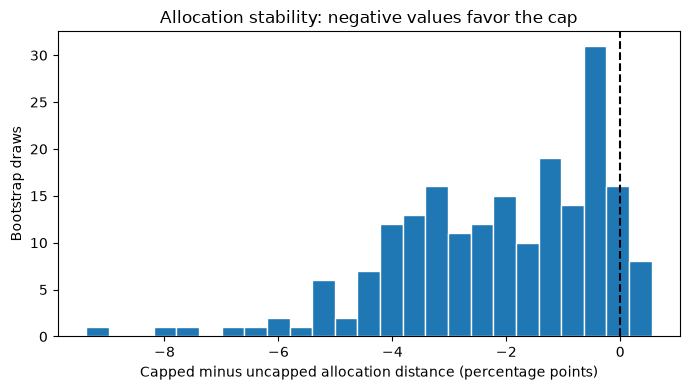

Saved new-contribution outputs to /Users/xiyuanzhu/QMIM_project/qmim_results/new_contribution


In [53]:
import matplotlib.pyplot as plt
from pathlib import Path
import hashlib, json
new_output = Path("qmim_results") / "new_contribution"
new_output.mkdir(parents=True, exist_ok=True)
bootstrap_results.to_csv(new_output / "bootstrap_draws.csv", index=False)
summary.to_csv(new_output / "stability_summary.csv")
paired_summary.to_csv(new_output / "paired_summary.csv")
# Save final PERMNOs explicitly; the original selection export precedes replacement.
pd.DataFrame({"permno": R_clean.columns}).to_csv(new_output / "final_2019_permnos.csv", index=False)
manifest = dict(B=B, mean_block=MEAN_BLOCK, seed=SEED,
    start=str(R_clean.index.min()), end=str(R_clean.index.max()),
    input_sha256=hashlib.sha256(R_clean.to_csv().encode()).hexdigest())
(new_output / "parameters.json").write_text(json.dumps(manifest, indent=2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(100*delta, bins=25, edgecolor="white")
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="Capped minus uncapped allocation distance (percentage points)",
       ylabel="Bootstrap draws", title="Allocation stability: negative values favor the cap")
fig.tight_layout()
fig.savefig(new_output / "allocation_stability.png", dpi=160)
plt.show()
print("Saved new-contribution outputs to", new_output.resolve())
